In [1]:
import zipfile
import os
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split
from scipy.signal import convolve2d
import pathlib
from sklearn.preprocessing import LabelEncoder

C:\Users\thaim\anaconda3\envs\tf210\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
#importing dataset
#Let's get our data from directory
trainds = {}
valds = {}

In [ ]:
trainds["v1_3540"] = tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/prpc_ver1_sigmax10_gain2",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
trainds["v2_3540"]=tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/prpc_ver2_sigmax10_gain2",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
trainds["v1_grscl_3540"]=tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/prpc_ver1_sigmax10_gain2_grscl",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
trainds["v2_grscl_3540"]=tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/prpc_ver2_sigmax10_gain2_grscl",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)

Found 3540 files belonging to 5 classes.
Found 3540 files belonging to 5 classes.
Found 3540 files belonging to 5 classes.
Found 3540 files belonging to 5 classes.


In [6]:
valds["v1_1770"]= tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver1_sigmax10_gain2",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
valds["v2_1770"]=tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver2_sigmax10_gain2",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
valds["v1_grscl_1770"]=tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver1_sigmax10_gain2_grscl",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
valds["v2_grscl_1770"]=tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver2_sigmax10_gain2_grscl",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)

Found 1770 files belonging to 5 classes.
Found 1770 files belonging to 5 classes.
Found 1770 files belonging to 5 classes.
Found 1770 files belonging to 5 classes.


In [7]:
valds["v1_17000"]= tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver1_sigmax10_gain2_17000",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
valds["v2_17000"]=tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver2_sigmax10_gain2_17000",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
valds["v1_grscl_17000"]=tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver1_sigmax10_gain2_grscl_17000",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
valds["v2_grscl_17000"]=tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver2_sigmax10_gain2_grscl_17000",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)

Found 17000 files belonging to 5 classes.
Found 17000 files belonging to 5 classes.
Found 17000 files belonging to 5 classes.
Found 17000 files belonging to 5 classes.


In [4]:
ds = {}

In [ ]:
ds["v2_masked_35108"]=tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/prpc_ver2_sigmax10_gain2_masked_35108",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)

Found 35108 files belonging to 5 classes.


In [5]:
ds["v2_masked_3540"] = tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/prpc_ver2_sigmax10_gain2_masked_3540",
    batch_size=50,
    seed=42,
    label_mode = "categorical",
    image_size=(224,224)
)

Found 3540 files belonging to 5 classes.


In [6]:
#Later on ,there will be models that contains these preprocessing built in their layers, which these functions won't be necessary

def to_grayscale(img, label):
    """Convert RGB image to single‐channel grayscale."""
    gray = tf.image.rgb_to_grayscale(img)
    return gray, label
def to_rgb(img, label):
    """Convert RGB image to single‐channel grayscale."""
    gray = tf.image.grayscale_to_rgb(img)
    return gray, label
def normalize(img, label):
    """Cast to float32 and scale pixels to [0,1]."""
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

#### There are a lot of separated imported dataset which doesn't appear like consistent method of training , is because i'm getting not ideal results from some trainings so i popped out new ideas of preprocessing to test, then re import different dataset, i'm learning, and exploring 

In [11]:
#splitting dataset
def split_data(ds,data_size = None,batch_size=50):
    ds = ds.unbatch()
    
    if data_size == None :
        try:
            data_size = len(data)
        except:
            print("Data length unknown")
            return
    else :
        split = 0.2
        val_size = int(data_size*split)
    #print(val_size)
    shuffled = ds.shuffle(buffer_size = data_size, seed=42)
    
    val = shuffled.take(val_size)
    train = shuffled.skip(val_size)
    
    val = val.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    train = train.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return train,val

In [12]:
#trainds["v1"],valds["v1"] = split_data(dataset=v1_valds_17000,data_size = 17000,batch_size=16)
trainds["v2_masked_35108_splitted"],valds["v2_masked_35108_splitted"] = split_data(ds=ds["v2_masked_35108"],data_size = 35108,batch_size=16)

In [ ]:
trainds["v2_masked_3540_splitted"],valds["v2_masked_3540_splitted"] = split_data(ds=ds["v2_masked_3540"],data_size = 3540,batch_size=50)

In [8]:
def get_cnn_model(
    name="cnn_model",
    num_classes=2,
    grayscale=False,
    zoom_factor=0.1,
    rotation_factor=0.1,
):
    # determine channels & output settings
    color_channels = 1 if grayscale else 3
    if num_classes == 2:
        final_units = 1
        final_activation = "sigmoid"
        loss = tf.keras.losses.BinaryCrossentropy()
        metrics = ["accuracy"]
    else:
        final_units = num_classes
        final_activation = "softmax"
        loss = tf.keras.losses.CategoricalCrossentropy()
        metrics = ["accuracy"]

    model = tf.keras.Sequential(
        [
            tf.keras.layers.InputLayer(input_shape=(224, 224, color_channels)),
            tf.keras.layers.Rescaling(1.0 / 255.0),
            tf.keras.layers.RandomFlip("horizontal_and_vertical"),
            tf.keras.layers.RandomRotation(rotation_factor),
            tf.keras.layers.RandomZoom(zoom_factor),

            tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
            tf.keras.layers.MaxPooling2D(),

            tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
            tf.keras.layers.MaxPooling2D(),

            tf.keras.layers.Flatten(),
            tf.keras.layers.Dense(64, activation="relu"),
            tf.keras.layers.Dropout(0.5),
            tf.keras.layers.Dense(final_units, activation=final_activation),
        ],
        name=name,
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=loss,
        metrics=metrics,
    )
    return model


In [9]:
def get_efficientNetB3(
    input_size: int = 224,
    num_classes: int = 5,
    backbone_trainable: bool = False,
    dropout_rate: float = 0.5,
    l2_reg: float = 0.01,
    l1_activity_reg: float = 0.002,
    learning_rate: float = 1e-3,
):
    """
    Creates a transfer‐learning model for diabetic‐retinopathy classification
    based on EfficientNetB3 (pretrained on ImageNet). By default, the EfficientNet
    backbone is frozen (backbone_trainable=False). After initial training you can
    unfreeze a few top layers.

    Args:
      input_size:          Height & width of the input (they should be square).
      num_classes:         Number of output classes (e.g. 5 for DR grades 0–4).
      backbone_trainable:  If False, the ImageNet‐trained EfficientNetB3 layers
                           stay frozen. If True, all of them become trainable.
      dropout_rate:        Dropout rate applied just before the final dense.
      l2_reg:              L2 weight regularizer strength for the final Dense.
      l1_activity_reg:     L1 activity regularizer strength for the final Dense.
      learning_rate:       Learning rate for the Adamax optimizer.

    Returns:
      A compiled tf.keras.Model ready for fit(…).
    """

    # 1) Build the EfficientNetB3 base (exclude top, ImageNet weights)
    base = tf.keras.applications.EfficientNetB3(
        include_top=False,
        weights="imagenet",
        input_shape=(input_size, input_size, 3),
        pooling="avg",
    )
    base.trainable = backbone_trainable

    # 2) Assemble the “head” on top of the frozen/finetunable backbone:
    inputs = tf.keras.Input(shape=(input_size, input_size, 3))

    # → Preprocessing (scales to ImageNet range)
    x = tf.keras.applications.efficientnet.preprocess_input(inputs)

    # → Backbone features
    x = base(x)

    # → BatchNorm (helps stabilize)
    x = tf.keras.layers.BatchNormalization(momentum=0.99, epsilon=1e-3)(x)

    # → Dropout for regularization
    x = tf.keras.layers.Dropout(dropout_rate)(x)

    # → Final Dense with both L2 on weights and L1 on activations
    x = tf.keras.layers.Dense(
        units=num_classes,
        activation="softmax",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
        activity_regularizer=tf.keras.regularizers.l1(l1_activity_reg),
    )(x)

    model = tf.keras.Model(inputs, x, name="EffNetB3_transfer")

    # 3) Compile
    model.compile(
        optimizer=tf.keras.optimizers.Adamax(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model


In [21]:
#setup cosine decay learning rate
num_train_imgs = 3540
batch_size     = 16
epochs         = 100
initial_lr     = 1e-3

steps_per_epoch = (num_train_imgs + batch_size - 1) // batch_size
decay_steps     = steps_per_epoch * epochs

cosine_decay = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=initial_lr,
    decay_steps=decay_steps,
    alpha=0.0
)

def lr_fn(epoch, lr):
    global_step = epoch * steps_per_epoch
    return float(cosine_decay(global_step).numpy())

lr_schedule = tf.keras.callbacks.LearningRateScheduler(lr_fn, verbose=1)

#### Let's train models

In [28]:
ds_keys,trainds_keys,valds_keys = [k for k,v in ds.items()],[k for k,v in trainds.items()],[k for k,v in valds.items()]
print("DS :",ds_keys,"\nTRAIN :",trainds_keys,"\nVAL:",valds_keys)

DS : ['v2_masked_35108', 'v2_masked_3540'] 
TRAIN : ['v1_3540', 'v2_3540', 'v1_grscl_3540', 'v2_grscl_3540', 'v2_masked_35108_splitted', 'v2_masked_3540_splitted'] 
VAL: ['v1_1770', 'v2_1770', 'v1_grscl_1770', 'v2_grscl_1770', 'v1_17000', 'v2_17000', 'v1_grscl_17000', 'v2_grscl_17000', 'v2_masked_35108_splitted', 'v2_masked_3540_splitted']


In [12]:
mdl_ENB3 = {}

In [9]:
mdl_ENB3["v2_masked"] = get_efficientNetB3()

In [15]:
#mdl_ENB3["v2_masked"]=get_efficientNetB3(backbone_trainable=True)
#mdl_ENB3["v2_masked"].load_weights('models_weights/mdl_ENB3_v2_masked_weights.h5')

In [29]:
history_mdl_ENB3 = {}

In [ ]:
#BBF -> BACKBONE FALSE
history_mdl_ENB3["v2_masked_3540_BBF"]=mdl_ENB3["v2_masked"].fit(trainds["v2_masked_3540"],validation_data=valds["v2_masked_3540"],epochs=100,verbose=1)

In [19]:
#mdl_ENB3["v2_masked"].save_weights("models_weights/mdl_ENB3_v2_masked_weights.h5")


In [18]:
mdl_ENB3["v2_masked"].evaluate(valds["v2_masked_35108"])

219/219 [==============================] - 176s 81ms/step - loss: 1.3458 - accuracy: 0.3770


[1.3457914590835571, 0.376997709274292]

In [ ]:
#let's now activate backbone training for mdl_ENB3 (efficientNet B3)
mdl_ENB3["v2_masked"].layers[1].trainable = True

In [17]:
#update optimizer of imbalanced classes
from tensorflow_addons.optimizers import AdamW
mdl_ENB3["v2_masked"].compile(
    optimizer=AdamW(learning_rate=2e-4, weight_decay=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
#compute class weights
images_per_class = {0:    25802,
2:     5288,
1 :    2438,
3  :    872,
4   :   708
}

total_images = 35108
class_weights = {
    cls : total_images/(n*5) for cls,n in images_per_class.items()
}

In [20]:
#setup early stop
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
#BBT -> BACKBONE TRUE
history_mdl_ENB3["v2_masked_3540_BBT"] = mdl_ENB3["v2_masked"].fit(
    trainds["v2_masked_35108"],
    validation_data=valds["v2_masked_35108"],
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

In [36]:
#mdl_ENB3["v2_masked"].save_weights("models_weights/mdl_ENB3_v2_masked_weights.h5")

In [34]:
#let's try training on smaller , balanced dataset again with backbone_trainable = True
history_mdl_ENB3["v2_masked_3540_BBT (2)"] = mdl_ENB3["v2_masked"].fit(
    trainds["v2_masked_35108"],
    validation_data=valds["v2_masked_35108"],
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
1974/1974 [==============================] - 1009s 434ms/step - loss: 1.0533 - accuracy: 0.4776 - val_loss: 1.1146 - val_accuracy: 0.5377
Epoch 2/10
1974/1974 [==============================] - 1083s 470ms/step - loss: 0.8730 - accuracy: 0.5188 - val_loss: 0.9061 - val_accuracy: 0.6321
Epoch 3/10
1974/1974 [==============================] - 1126s 481ms/step - loss: 0.7959 - accuracy: 0.5412 - val_loss: 1.0088 - val_accuracy: 0.5248
Epoch 4/10
1974/1974 [==============================] - 1158s 490ms/step - loss: 0.7019 - accuracy: 0.5732 - val_loss: 0.8731 - val_accuracy: 0.6107
Epoch 5/10
1974/1974 [==============================] - 1203s 501ms/step - loss: 0.6647 - accuracy: 0.5883 - val_loss: 0.7412 - val_accuracy: 0.6832
Epoch 6/10
1974/1974 [==============================] - 1247s 516ms/step - loss: 0.5654 - accuracy: 0.6275 - val_loss: 0.7075 - val_accuracy: 0.7100
Epoch 7/10
1974/1974 [==============================] - 1291s 530ms/step - loss: 0.5091 - accuracy: 0.6687

In [35]:
mdl_ENB3["v2_masked"].evaluate(valds["v2_masked_35108"])
mdl_ENB3["v2_masked"].evaluate(valds["v2_masked_3540"])

18/18 [==============================] - 7s 107ms/step - loss: 0.1603 - accuracy: 0.9571


[0.16033406555652618, 0.9571428298950195]

In [36]:
#mdl_ENB3["v2_masked"].save_weights("models_weights/mdl_ENB3_v2_masked_weights.h5")

In [38]:
# Prepare the history DataFrame
def plot_modelMetrics(h,title="model metrics",fname="model_metrics.png"):
    df = pd.DataFrame(h.history)
    num_epochs = len(df)
    step       = max(1, num_epochs // 10)
    positions  = list(range(0, num_epochs, step))
    
    # Dark background style
    plt.style.use('dark_background')
    fig, (ax1, ax2) = plt.subplots(
        1, 2,
        figsize=(14, 6),
        dpi=300,
        facecolor='black'
    )
    for ax in (ax1, ax2):
        ax.set_facecolor('black')
        ax.grid(True, color='#555555', linestyle='--', linewidth=0.5)
    
    # ─── Accuracy subplot ────────────────────────────────────────────
    ax1.plot(
        df['accuracy'],marker="x",markersize=4, linewidth=1, color='#39FF14',
        label='Train Acc'
    )
    ax1.plot(
        df['val_accuracy'],marker="x",markersize=4,linewidth=1, color='#FF0090',
        label='Val Acc'
    )
    ax1.set_title('Accuracy', color='#39FF14', fontsize=16, pad=10)
    ax1.set_xlabel('Epoch', color='#39FF14')
    ax1.set_ylabel('Accuracy', color='#39FF14')
    ax1.set_ylim(0, 1)
    ax1.set_xticks(positions)
    ax1.set_xticklabels(positions, rotation=45, color='#39FF14')
    ax1.tick_params(axis='y', colors='#39FF14')
    leg1 = ax1.legend(facecolor='black', edgecolor='#39FF14')
    for text in leg1.get_texts(): text.set_color('#39FF14')
    
    # ─── Loss subplot ─────────────────────────────────────────────────
    ax2.plot(
        df['loss'],marker="x",markersize=4 ,linewidth=1, color='#00FFFF',
        label='Train Loss'
    )
    ax2.plot(
        df['val_loss'],marker="x",markersize=4, linewidth=1, color='#FFA500',
        label='Val Loss'
    )
    ax2.set_title('Loss', color='#00FFFF', fontsize=16, pad=10)
    ax2.set_xlabel('Epoch', color='#00FFFF')
    ax2.set_ylabel('Loss', color='#00FFFF')
    # autoscale y to data range, with a little padding
    ymin = df[['loss','val_loss']].min().min() * 0.9
    ymax = df[['loss','val_loss']].max().max() * 1.1
    ax2.set_ylim(ymin, ymax)
    ax2.set_xticks(positions)
    ax2.set_xticklabels(positions, rotation=45, color='#00FFFF')
    ax2.tick_params(axis='y', colors='#00FFFF')
    leg2 = ax2.legend(facecolor='black', edgecolor='#00FFFF')
    for text in leg2.get_texts(): text.set_color('#00FFFF')
    
    # Supertitle and layout
    fig.suptitle(title, color='white', fontsize=18, y=1.02)
    plt.tight_layout()
    
    # Display
    plt.show()
    
    # Save the figure
    fig.savefig(
        fname,
        dpi=300,
        facecolor=fig.get_facecolor(),
        edgecolor='black',
        bbox_inches='tight'
    )


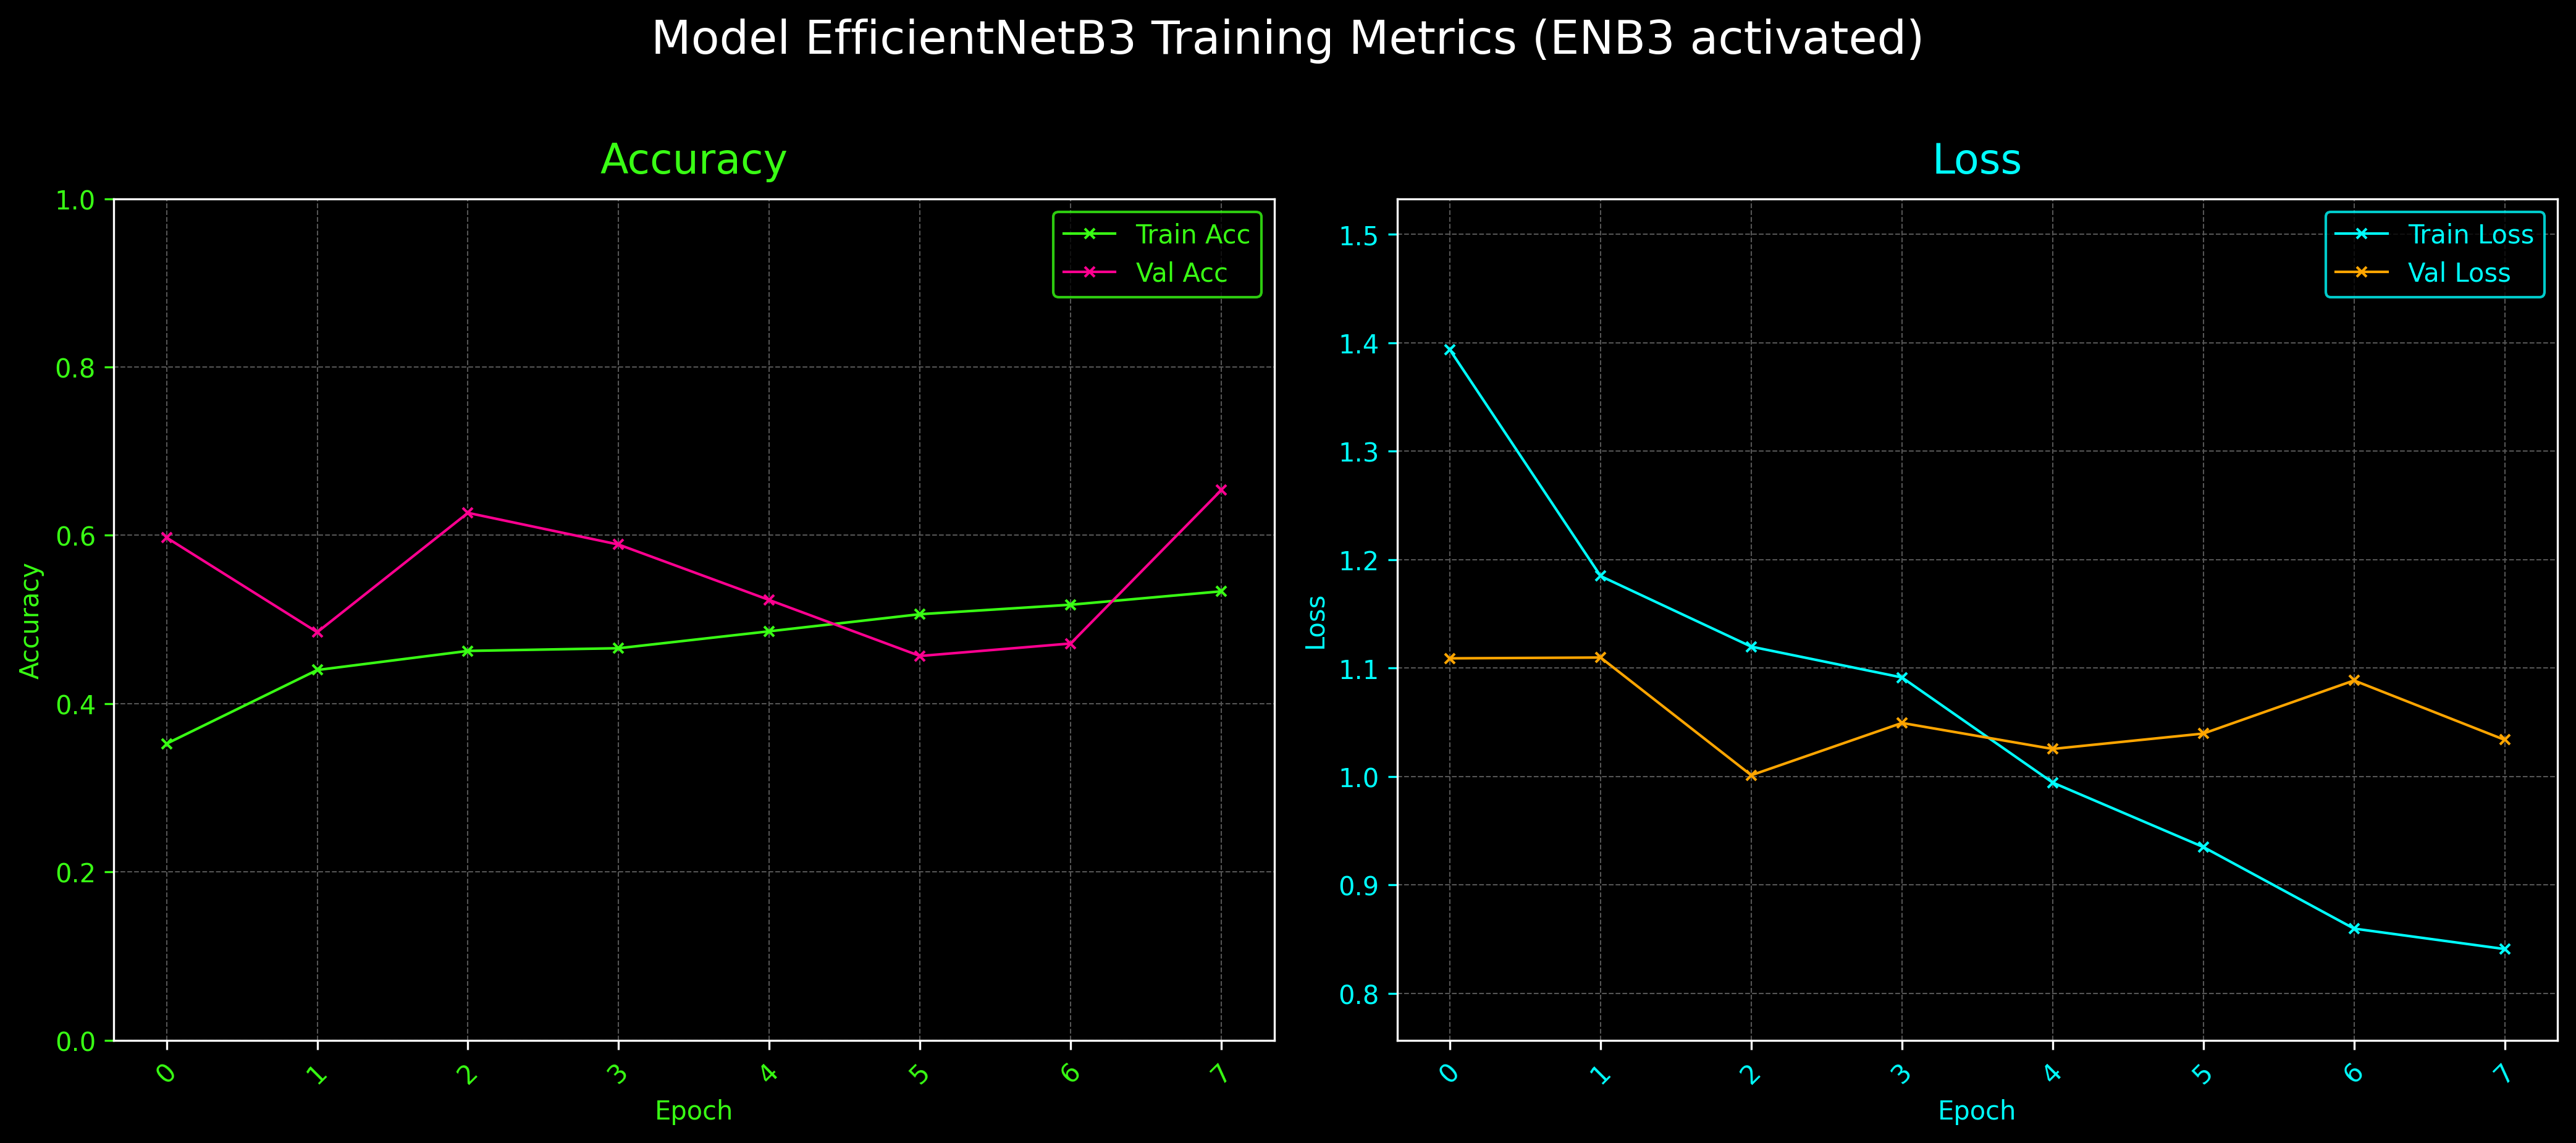

In [35]:
plot_modelMetrics(history["v2_masked_3540_BBT"],title='Model EfficientNetB3 Training Metrics (ENB3 activated)',fname='mdl_ENB3_v2_masked_35108_metrics.png')

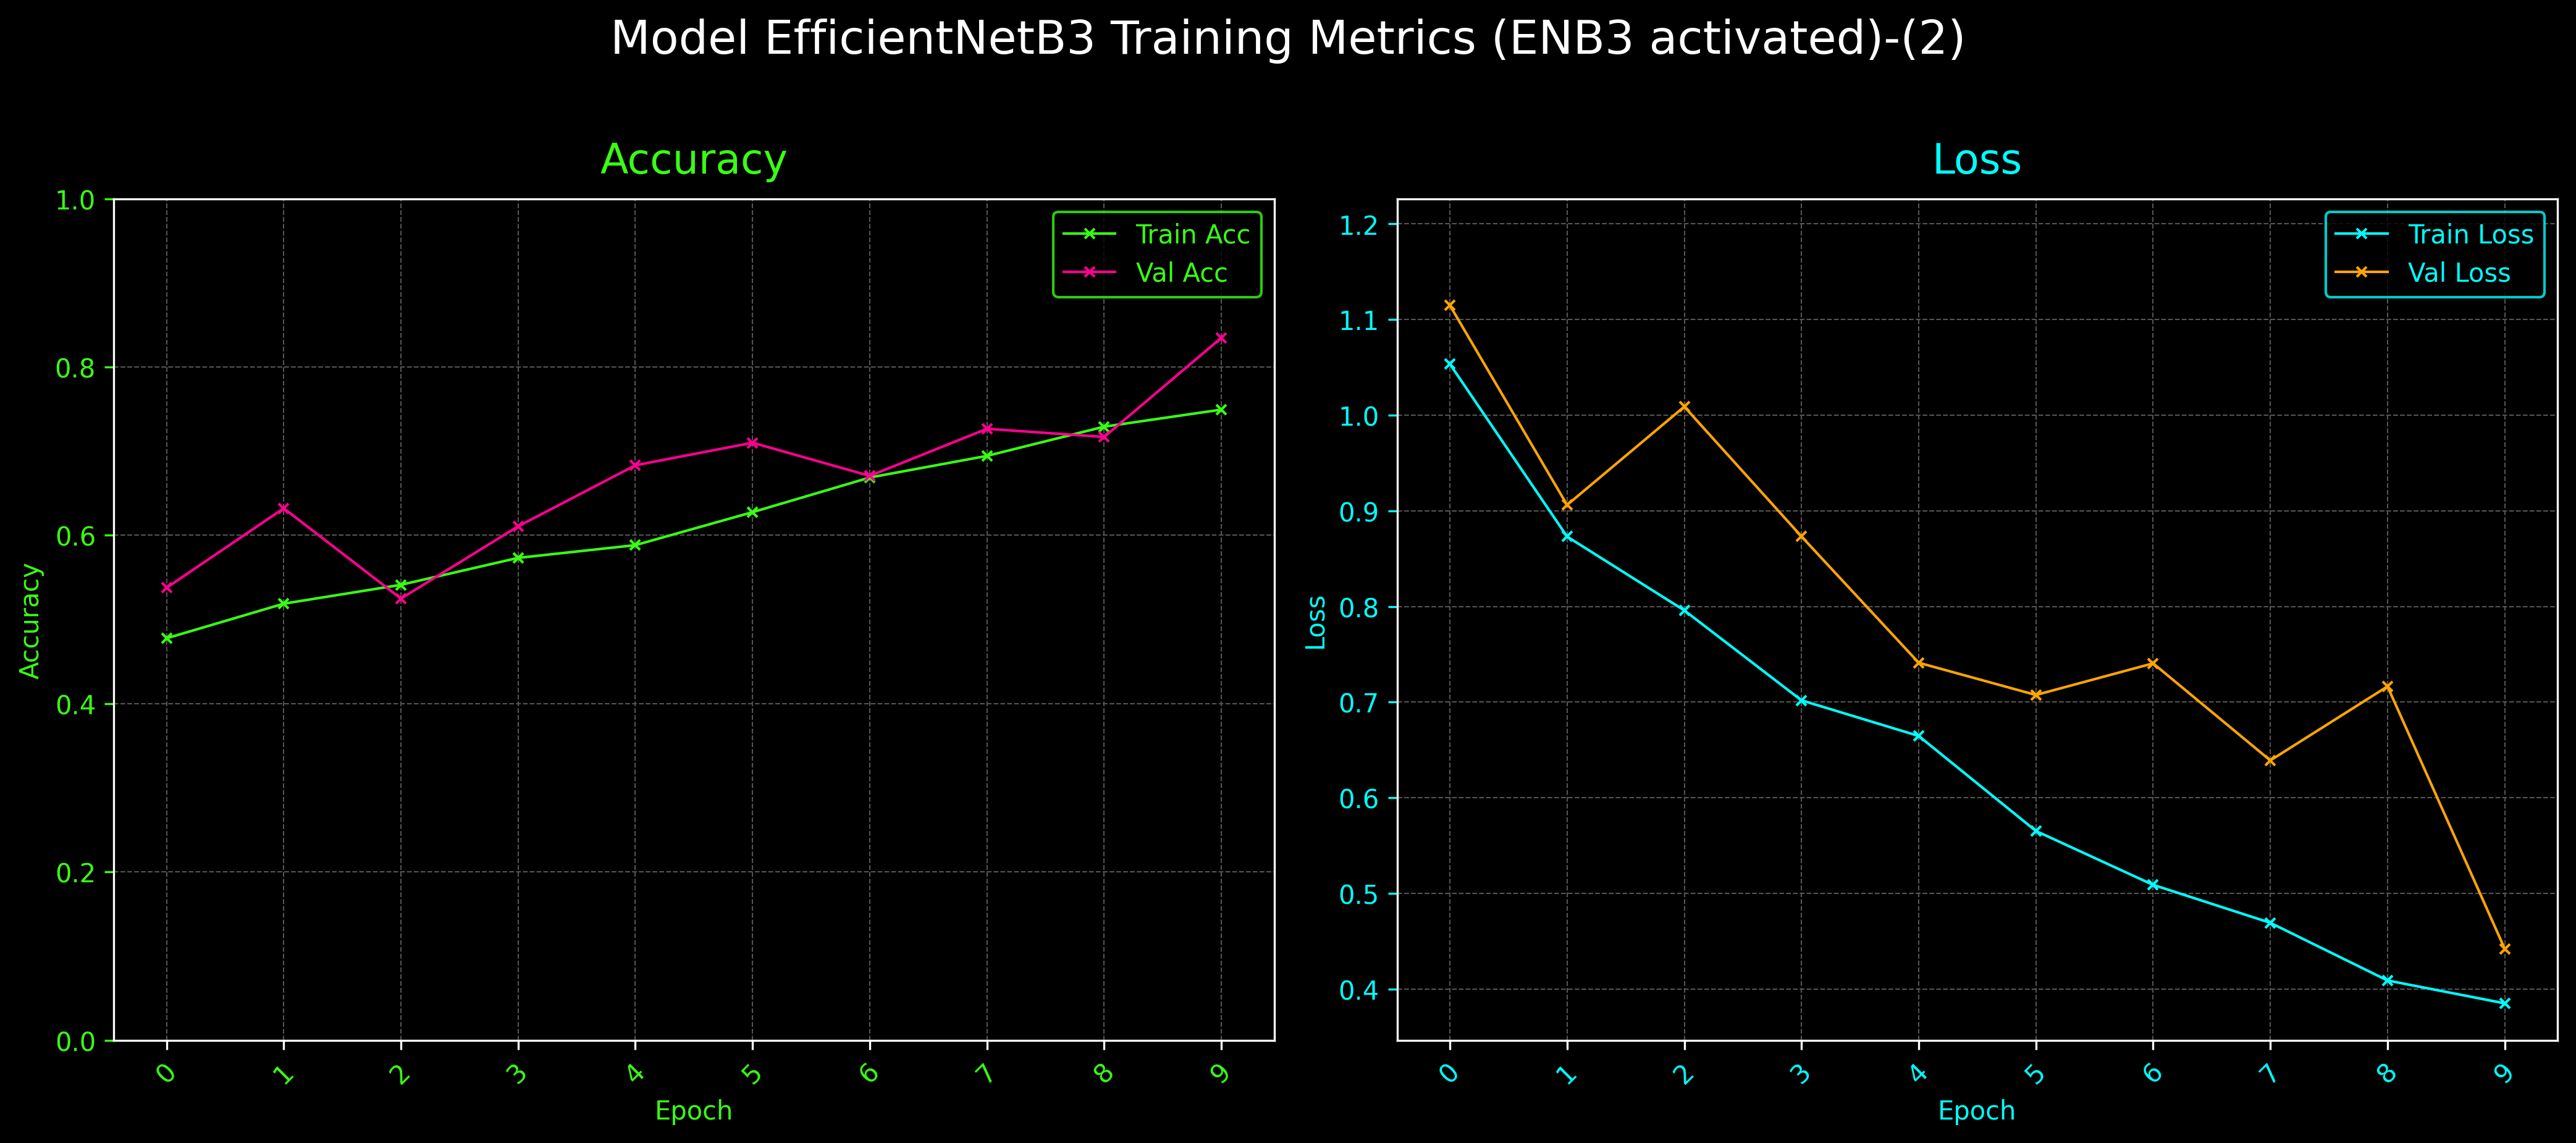

In [39]:
plot_modelMetrics(history["v2_masked_3540_BBT (2)"],title='Model EfficientNetB3 Training Metrics (ENB3 activated)-(2)',fname='mdl_ENB3_v2_masked_3540_metrics(2).png')

#### Let's test training on a simpler model to see if it can learn fitting large training dataset

In [62]:
mdl_sequential={}
mdl_sequential["v2_masked"] = get_cnn_model()
history_mdl_sequential = {}
history_mdl_sequential["v2_masked"] = mdl_sequential["v2_masked"].fit(trainds["v2_masked_35108_splitted"],
                                                         validation_data=valds["v2_masked_35108_splitted"],
                                                         epochs=10,
                                                         callbacks=[early_stop],
                                                         verbose=1)

Epoch 1/10
1756/1756 [==============================] - 649s 316ms/step - loss: 0.8974 - accuracy: 0.7350 - val_loss: 0.8762 - val_accuracy: 0.7376
Epoch 2/10
1756/1756 [==============================] - 792s 386ms/step - loss: 0.8848 - accuracy: 0.7344 - val_loss: 0.8674 - val_accuracy: 0.7329
Epoch 3/10
1756/1756 [==============================] - 850s 402ms/step - loss: 0.8806 - accuracy: 0.7344 - val_loss: 0.8643 - val_accuracy: 0.7334
Epoch 4/10
1756/1756 [==============================] - 911s 422ms/step - loss: 0.8760 - accuracy: 0.7349 - val_loss: 0.8798 - val_accuracy: 0.7295
Epoch 5/10
1756/1756 [==============================] - 956s 435ms/step - loss: 0.8815 - accuracy: 0.7313 - val_loss: 0.8705 - val_accuracy: 0.7329
Epoch 6/10
1756/1756 [==============================] - 991s 440ms/step - loss: 0.8740 - accuracy: 0.7337 - val_loss: 0.8780 - val_accuracy: 0.7288
Epoch 7/10
1756/1756 [==============================] - 1014s 445ms/step - loss: 0.8661 - accuracy: 0.7365 - val

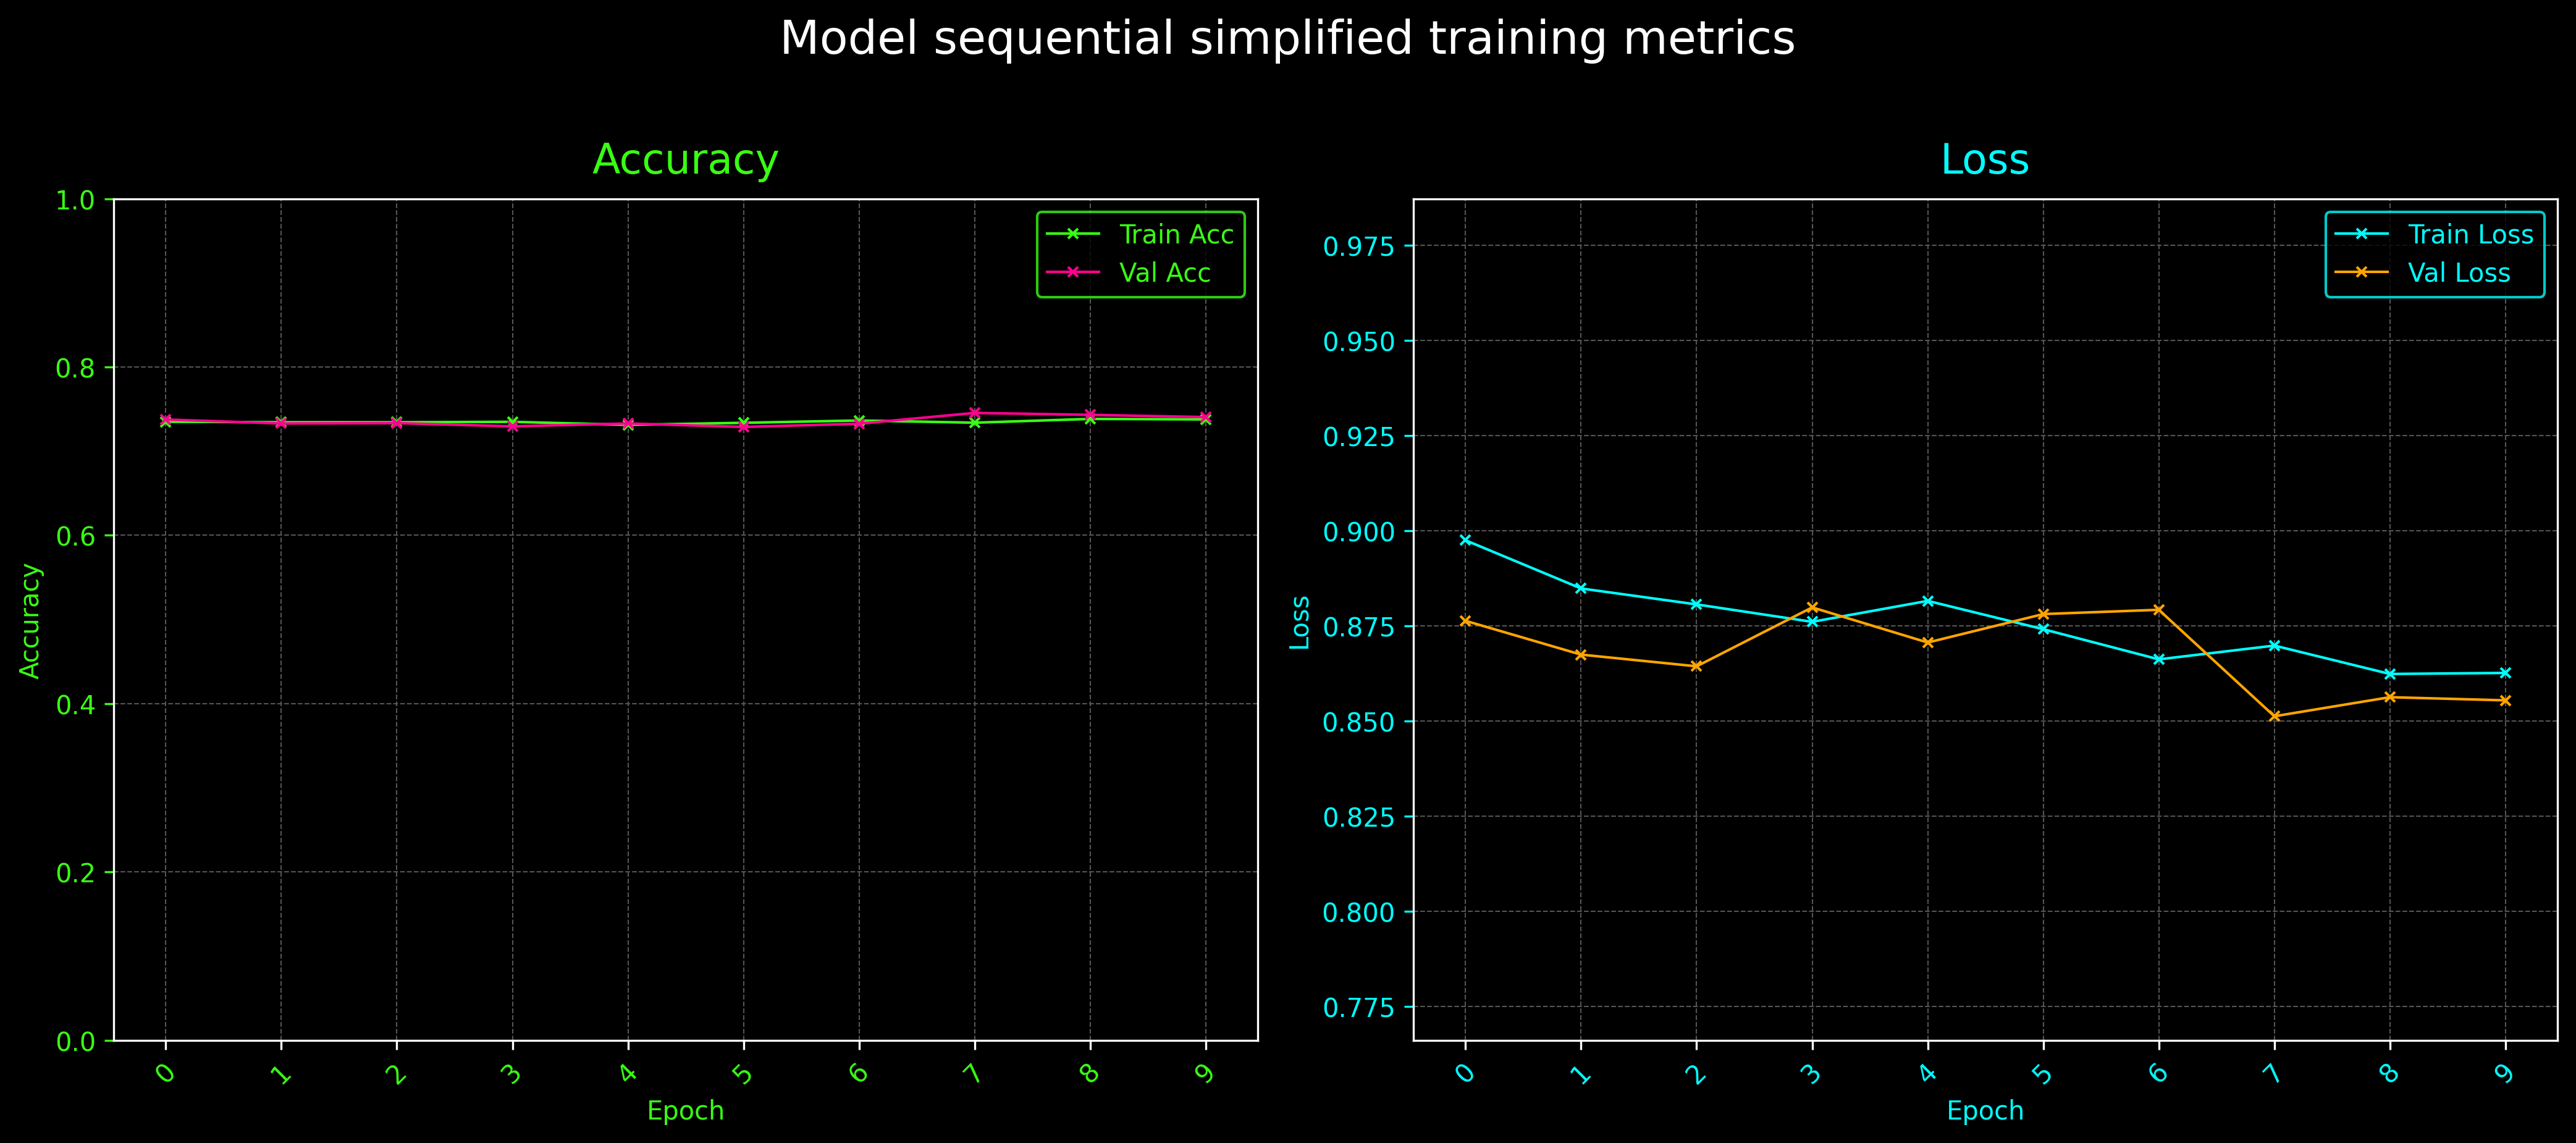

In [68]:
plot_modelMetrics(history_mdl_sequential["v2_masked"],title = "Model sequential simplified training metrics",fname= "mdl_sequential_simplified_35108_metrics.png")

### Let's train binary classification model to detect retino/not retina

In [31]:
trainds = {}
valds = {}

In [32]:
ds = {}
ds["fundus binary classification"] = tf.keras.utils.image_dataset_from_directory(
    "dataset/binary classification dataset",
    seed = 42,
    batch_size = 50,
    label_mode = "binary",
    image_size = (224,224)
)

Found 10310 files belonging to 2 classes.


In [33]:
ds["fundus binary classification"] = (
    ds["fundus binary classification"]
    .map(to_grayscale,
         num_parallel_calls=tf.data.AUTOTUNE)
)

In [34]:
trainds["fundus binary classification"],valds["fundus binary classification"] = split_data(ds=ds["fundus binary classification"],data_size = 10310,batch_size = 20)

In [23]:
for i,l in trainds["fundus binary classification"].take(1):
    print("i:",i.shape," l:",l.shape)

i: (20, 224, 224, 1)  l: (20, 2)


In [35]:
models = {}
models["binary classification"] = get_cnn_model(grayscale = True,num_classes=2)

In [36]:
histories = {}
histories["binary classification"] = models["binary classification"].fit(trainds["fundus binary classification"],validation_data = valds["fundus binary classification"], epochs = 100, verbose =1,callbacks=[early_stop])

Epoch 1/100
413/413 [==============================] - 173s 302ms/step - loss: 0.0748 - accuracy: 0.9771 - val_loss: 0.0698 - val_accuracy: 0.9825
Epoch 2/100
413/413 [==============================] - 192s 410ms/step - loss: 0.0149 - accuracy: 0.9954 - val_loss: 0.0104 - val_accuracy: 0.9971
Epoch 3/100
413/413 [==============================] - 182s 410ms/step - loss: 0.0156 - accuracy: 0.9945 - val_loss: 0.0108 - val_accuracy: 0.9966
Epoch 4/100
413/413 [==============================] - 183s 411ms/step - loss: 0.0154 - accuracy: 0.9959 - val_loss: 0.0088 - val_accuracy: 0.9976
Epoch 5/100
413/413 [==============================] - 183s 412ms/step - loss: 0.0100 - accuracy: 0.9970 - val_loss: 0.0067 - val_accuracy: 0.9981
Epoch 6/100
413/413 [==============================] - 182s 409ms/step - loss: 0.0153 - accuracy: 0.9956 - val_loss: 0.0062 - val_accuracy: 0.9990
Epoch 7/100
413/413 [==============================] - 184s 412ms/step - loss: 0.0148 - accuracy: 0.9955 - val_loss: 0

In [37]:
models["binary classification"].save_weights("models_weights/binary_classification_weights.h5")

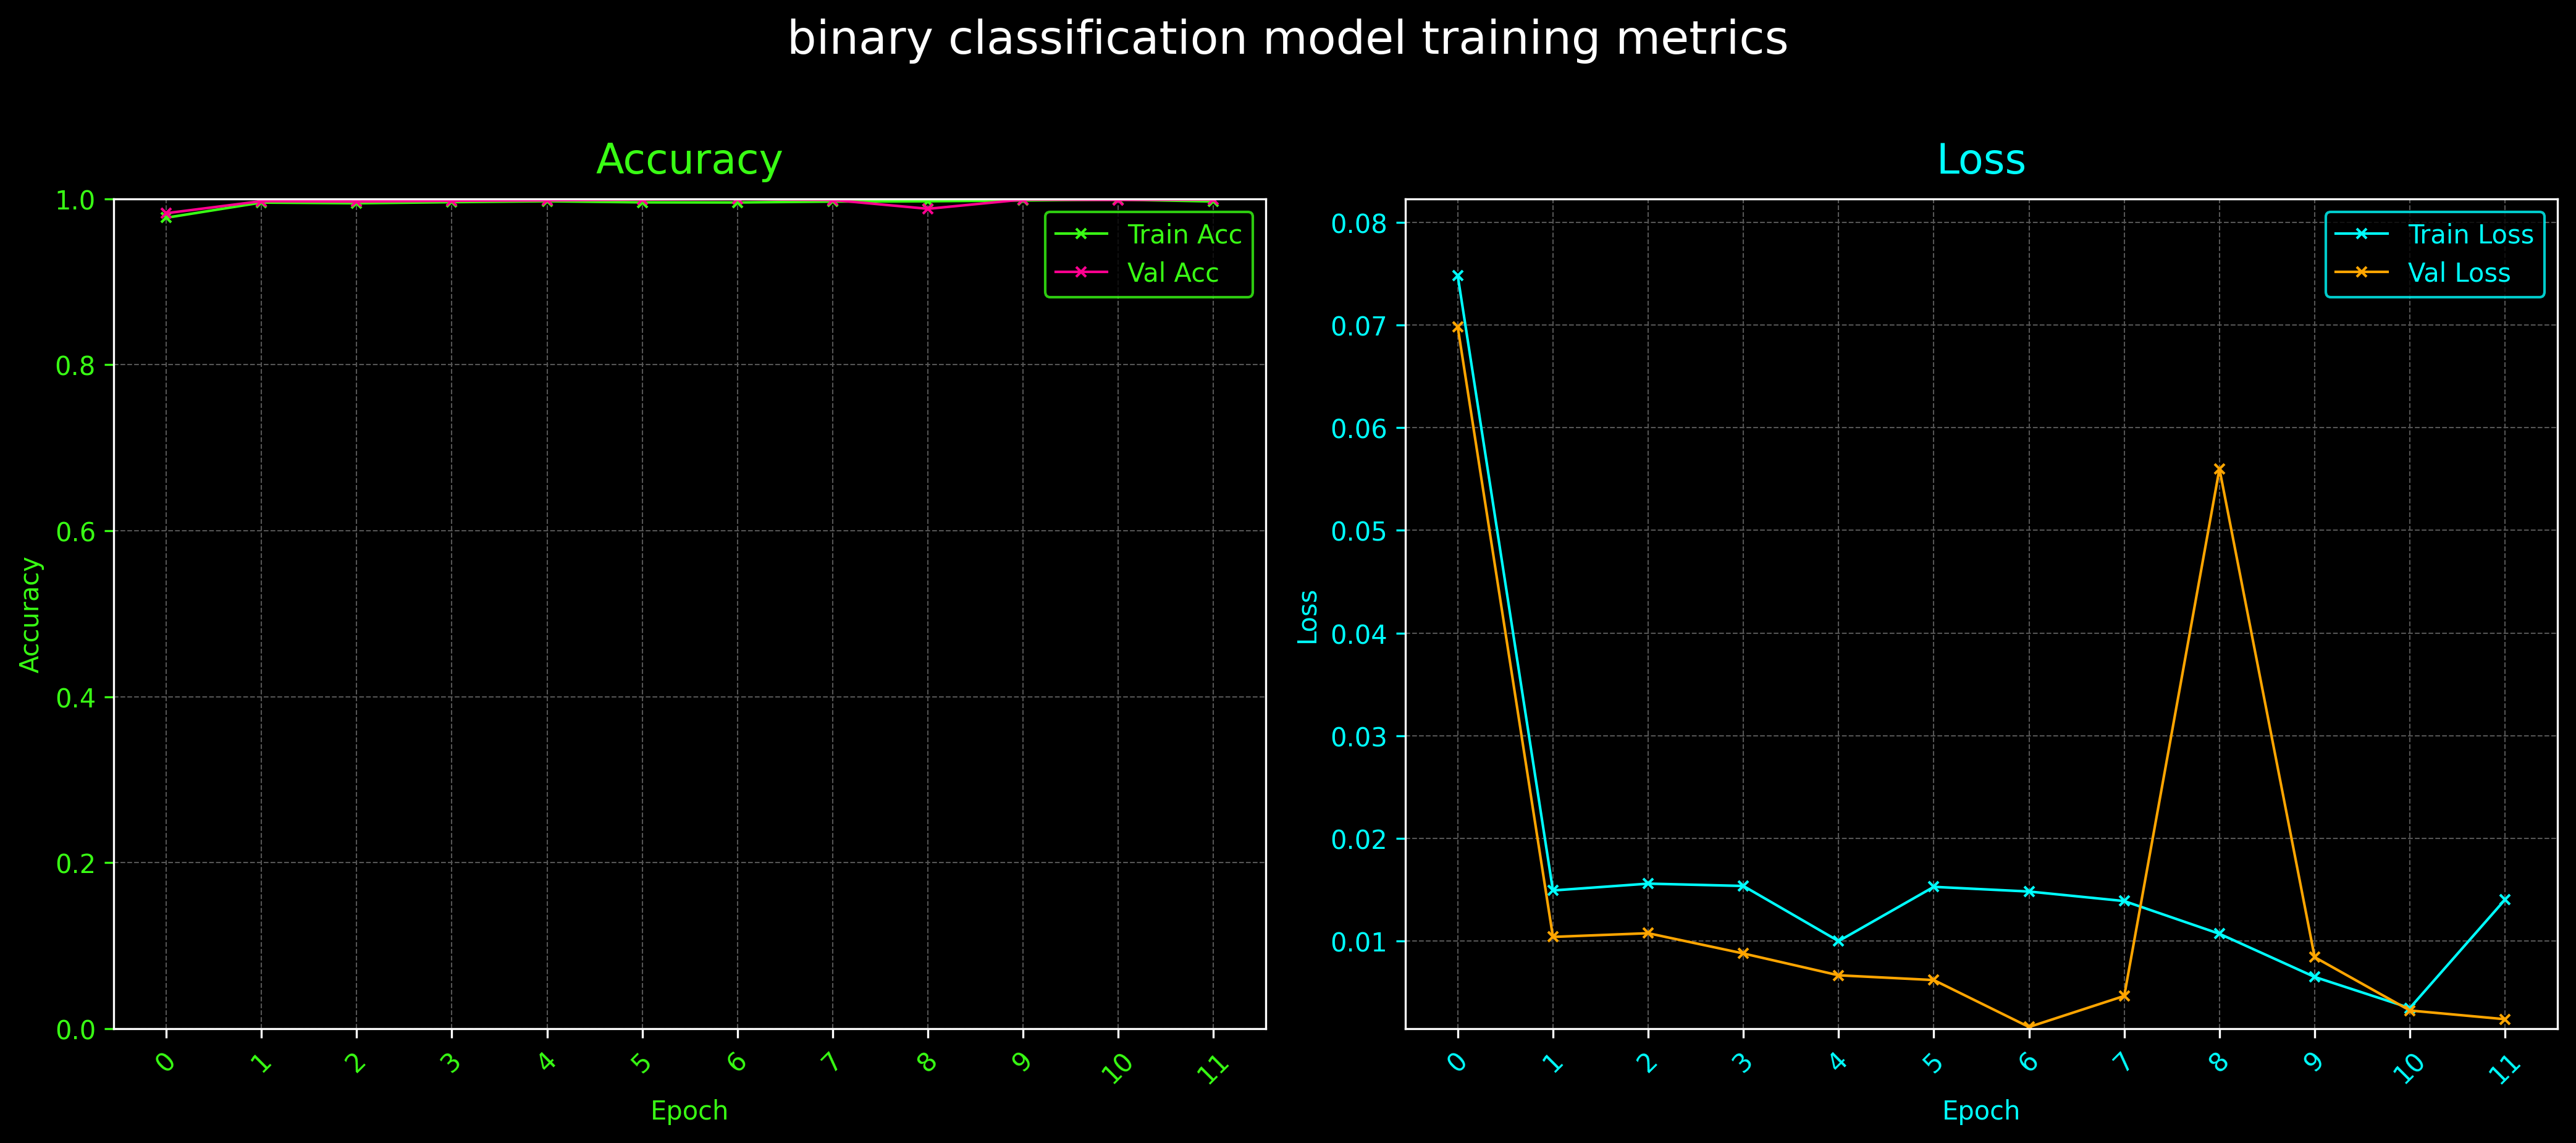

In [39]:
plot_modelMetrics(histories["binary classification"],title = "binary classification model training metrics",fname= "binary_classification_model_metrics.png")

In [1]:
def plot_models_evaluation(models_eval, title="Models evaluation",
                           title_fs=20, label_fs=14, tick_fs=12, bar_width=0.6,
                          fname="Models_evaluation.png",normalize=False):
    max_loss = max(metrics[0] for metrics in models_eval.values())
    loss_label = "loss"
    if normalize :
        loss_label = f"Loss/Max_Loss({max_loss:.1f}) %"
    
    """
    Plots evaluation metrics (Loss, Accuracy, AUC) for multiple models
    with adjustable font sizes and bar widths.
    """
    # Convert dict to list of tuples if necessary
    if isinstance(models_eval, dict):
        items = list(models_eval.items())
    else:
        items = models_eval

    # Neon color palette
    neon_colors = [
        "#BFFF00", "#E500FF", "#76FF7A", "#00FFEF",
        "#39FF14", "#FF6EC7", "#04D9FF", "#F4F142",
        "#FF3131", "#FF5F1F",
    ]
    categories = [loss_label, "Accuracy", "AUC"]
    num_eval   = len(items)
    rows       = num_eval // 2 + num_eval % 2
    cols       = 2 if num_eval > 1 else 1

    # Create subplots
    fig, axes = plt.subplots(
        rows, cols,
        figsize=(cols * 6, rows * 4),
        dpi=300,
        facecolor='black'
    )
    # Flatten axes array
    if hasattr(axes, 'flatten'):
        axes = axes.flatten()
    else:
        axes = [axes]

    # Style each subplot
    for ax, color in zip(axes, neon_colors):
        ax.set_facecolor('black')
        ax.grid(True, color=color, linestyle='--', linewidth=0.5)

    # Plot each model's evaluation
    for i, (model_name, evaluation) in enumerate(items):
        if normalize:
            evaluation = [
                val / max_loss if val > 1 else val
                for val in evaluation
            ]
        ax = axes[i]
        count = min(len(evaluation), len(categories))
        ax.bar(
            categories[:count],
            evaluation[:count],
            color=neon_colors[i],
            width=bar_width  # Adjust bar width here
        )
        # Axis labels and title with adjustable font sizes
        #ax.set_xlabel('Metrics', color='white', fontsize=label_fs)
        ax.set_ylim(0, 1)
        ax.set_ylabel('Score', color='white', fontsize=label_fs)
        ax.set_title(model_name, color=neon_colors[i], fontsize=label_fs + 2)
        # Tick label sizes
        ax.set_xticks(categories[:count])
        ax.set_xticklabels(categories[:count], color='white', fontsize=tick_fs)
        ax.tick_params(axis='y', colors='white', labelsize=tick_fs)

    # Figure title with adjustable font size
    fig.suptitle(title, color='white', fontsize=title_fs, y=1.02)
    plt.tight_layout()
    plt.show()
    fig.savefig(
        fname,
        dpi=300,
        facecolor=fig.get_facecolor(),
        edgecolor='black',
        bbox_inches='tight'
    )


In [14]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

In [ ]:
def plot_cm(model, data, class_names, input_color='Blues', title="Model", save_path=None):
    """
    Plot the confusion matrix for the entire dataset (unbatched).
    """
    # Unbatch the dataset to get all samples
    data_unbatched = data.unbatch()

    X_list, y_list = [], []

    for x, y in data_unbatched:
        X_list.append(x.numpy())
        y_list.append(y.numpy())

    X_all = np.stack(X_list)
    y_all = np.stack(y_list)
    y_true = np.argmax(y_all, axis=1)

    # Predict
    y_prob = model.predict(X_all, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, normalize='true') * 100

    # Plot
    fig, ax = plt.subplots(figsize=(8, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax,
              cmap=input_color,
              xticks_rotation=45,
              values_format='.2f')  
    ax.set_title(f"Confusion Matrix for {title} (in % of true class)")
    plt.tight_layout()

    # Save if specified
    if save_path:
        fig.savefig(save_path,
                    dpi=300,
                    facecolor=fig.get_facecolor(),
                    edgecolor='black',
                    bbox_inches='tight')

    plt.show()

In [10]:
model_ENB3 = get_efficientNetB3(backbone_trainable = True)
mdeol_binary = get_cnn_model()

In [11]:
model_ENB3.load_weights(f"{os.getcwd()}/models_weights/mdl_ENB3_v2_masked_weights.h5")

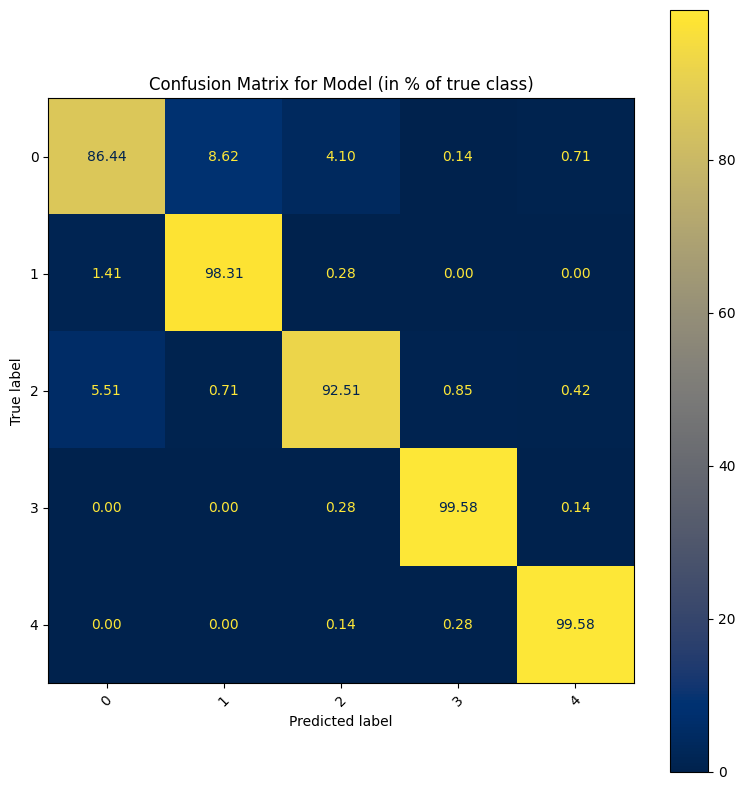

In [18]:
plot_cm(model=model_ENB3,data=ds["v2_masked_3540"],input_color ='cividis',class_names = ds["v2_masked_3540"].class_names,save_path="confusion_matrix.png")